Name : Luqman Khan

SID : S202266054

Section : V1

Course Code: CS4152

Semester: Fall 2026

Sumitted to: Dr. Jameel Ahmad

Course Title: Deep Learning and Neural Networks

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

1: Load the credit card **dataset**

In [ ]:
cc = pd.read_csv('/content/creditcard.csv')

print(cc.shape)

(284807, 31)


In [ ]:
import os, time, random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed()
sns.set()

os.makedirs('results', exist_ok=True)

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


Analyze class imbalance: document the percentage of legitimate vs. fraudulent
transactions

In [ ]:

counts = cc['Class'].value_counts()

pct = cc['Class'].value_counts(normalize=True) * 100

print('Legitimate (0): %d  (%.3f%%)' % (counts[0], pct[0]))

print('Fraudulent (1): %d  (%.3f%%)' % (counts[1], pct[1]))


Legitimate (0): 284315  (99.827%)
Fraudulent (1): 492  (0.173%)


Explanation:
- Class = 0 means a legitimate transaction.
- Class = 1 means a fraudulent transaction.
- value_counts() counts transactions in each class.
- normalize=True calculates each class's proportion.
- * 100 converts the proportions into percentages.
For the standard dataset, the results are approximately:
- Legitimate: 284,315 transactions (99.827%).
- Fraudulent: 492 transactions (0.173%).
Your actual output should confirm the values in your file.

3: Plot the class distribution

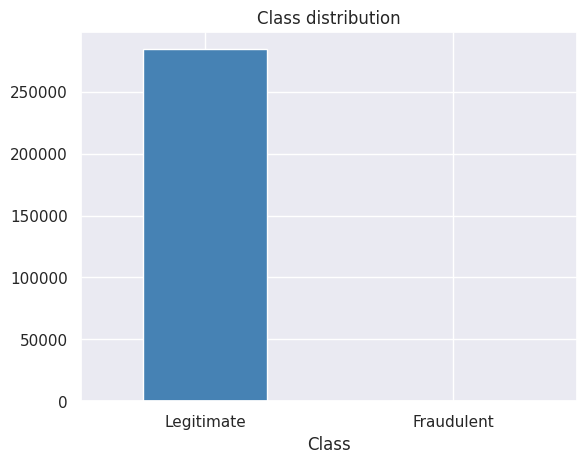

In [ ]:

cc['Class'].value_counts().plot(
    kind='bar',
    title='Class distribution',
    color=['steelblue', 'crimson']
)

plt.xticks(
    [0, 1],
    ['Legitimate', 'Fraudulent'],
    rotation=0
)

plt.show()


Explanation:

This bar chart shows that legitimate transactions greatly outnumber fraudulent transactions. This is called class imbalance.

Why is this important? A model could achieve very high accuracy by predicting almost every transaction as legitimate, while failing to detect fraud.

# **Task 2b — Prepare the input features**

**4: Separate features and labels**

In [ ]:
X = cc.drop(['Time', 'Class'], axis=1)
Y = cc['Class']

x_train, x_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    stratify=Y,
    random_state=0
)

print('Input features:', X.shape[1])

print(
    'Fraud %% in train: %.3f   Fraud %% in test: %.3f'
    % (y_train.mean() * 100, y_test.mean() * 100)
)

Input features: 29
Fraud % in train: 0.173   Fraud % in test: 0.172


Understand each line:
- X contains the 29 input features: V1 through V28 and Amount.
- Y contains the correct class label.
- Time is removed, as required by the notebook.
- test_size=0.2 reserves 20% for testing.
- stratify=Y preserves the class proportions in the training and testing sets.
- random_state=0 makes the split reproducible.

Input features: 29
Fraud % in train: approximately 0.173
Fraud % in test: approximately 0.173

# Task 2c — Compile and train

In [ ]:

def build_fraud_model():

    m = Sequential()

    m.add(Dense(128, activation='relu', input_dim=29))

    m.add(Dense(1, activation='sigmoid'))

    m.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

    return m


Explanation:
- Dense(128, activation='relu') creates 128 hidden neurons.
- input_dim=29 tells the network that each transaction has 29 input features.
- Dense(1, activation='sigmoid') creates one output for the fraud probability.
- binary_crossentropy measures the prediction error for two classes.
- adam updates the model's weights.
- accuracy tracks the fraction of correct predictions.

**6: Create and inspect the model**

In [ ]:

set_seed()

fraud_model = build_fraud_model()

fraud_model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,969 (15.50 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

**7: Train the model**

In [ ]:

hist_f = fraud_model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=10,
    batch_size=100
)


Epoch 1/10
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9987 - loss: 0.0218 - val_accuracy: 0.9993 - val_loss: 0.0056
Epoch 2/10
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9992 - loss: 0.0110 - val_accuracy: 0.9993 - val_loss: 0.0048
Epoch 3/10
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9993 - loss: 0.0091 - val_accuracy: 0.9993 - val_loss: 0.0042
Epoch 4/10
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9993 - loss: 0.0101 - val_accuracy: 0.9993 - val_loss: 0.0056
Epoch 5/10
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9994 - loss: 0.0081 - val_accuracy: 0.9993 - val_loss: 0.0044
Epoch 6/10
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9994 - loss: 0.0072 - val_accuracy: 0.9994 - val_loss: 0.0040
Epoch 7/10
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9994 - loss: 0.0071 - val_accuracy: 0.9993 - val_loss: 0.0098
Epoch 8/10
2279/2279 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9994 - loss: 0.0065 - 

Understand the parameters:
- x_train, y_train: data used to train the model.
- validation_data=(x_test, y_test): the notebook monitors performance on the test set during training.
- epochs=10: ten training passes.
- batch_size=100: 100 transactions per batch.

# Task 2d — Evaluate the model

**8: Plot training and validation accuracy**

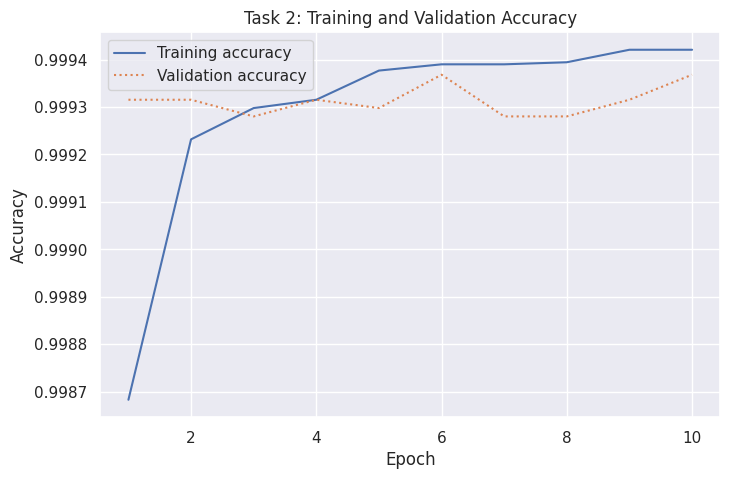

In [ ]:

acc = hist_f.history['accuracy']
val = hist_f.history['val_accuracy']

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(acc) + 1),
    acc,
    '-',
    label='Training accuracy'
)

plt.plot(
    range(1, len(val) + 1),
    val,
    ':',
    label='Validation accuracy'
)

plt.title('Task 2: Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.show()


The graph shows how accuracy changes over the ten epochs. Remember that accuracy alone cannot tell us how many fraudulent transactions the model catches.

**9: Create an evaluation function**

In [ ]:

labels = ['Legitimate', 'Fraudulent']

def evaluate_fraud(model, title):

    y_pred = (
        model.predict(x_test, verbose=0) > 0.5
    ).astype(int).ravel()

    cm = confusion_matrix(y_test, y_pred)

    tn, fp, fn, tp = cm.ravel()

    tpr = tp / (tp + fn)

    fpr = fp / (fp + tn)

    accuracy = (tp + tn) / cm.sum()

    ConfusionMatrixDisplay(
        cm,
        display_labels=labels
    ).plot(
        cmap='Blues',
        xticks_rotation='vertical'
    )

    plt.title(title)
    plt.grid(False)
    plt.show()

    print('TN=%d  FP=%d  FN=%d  TP=%d' % (tn, fp, fn, tp))

    print('True Positive Rate (fraud caught): %.4f' % tpr)

    print('False Positive Rate (false alarms): %.6f' % fpr)

    print('Overall accuracy: %.5f' % accuracy)

    return {
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'TPR': tpr,
        'FPR': fpr,
        'Accuracy': accuracy
    }


Understand the confusion matrix:
Term	Meaning
TN — True Negative	Legitimate transaction correctly classified
FP — False Positive	Legitimate transaction incorrectly flagged as fraud
FN — False Negative	Fraudulent transaction missed
TP — True Positive	Fraudulent transaction correctly detected

The prediction threshold is 0.5. If the model's output is greater than 0.5, it predicts fraud (1); otherwise, it predicts legitimate (0).

**10: Evaluate the model without class weights**

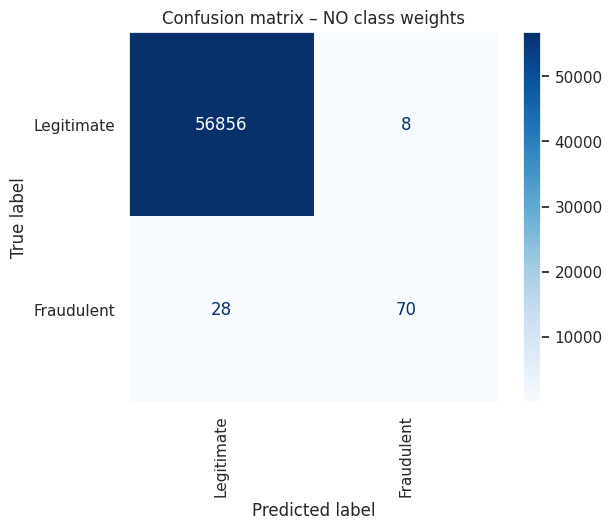

TN=56856  FP=8  FN=28  TP=70
True Positive Rate (fraud caught): 0.7143
False Positive Rate (false alarms): 0.000141
Overall accuracy: 0.99937


In [ ]:

res_before = evaluate_fraud(
    fraud_model,
    'Confusion matrix – NO class weights'
)


# Task 2d — Analysis answer

**Task 2d — Analysis**

The True Positive Rate (TPR) measures the percentage of fraudulent transactions correctly detected by the model. The False Positive Rate (FPR) measures the percentage of legitimate transactions incorrectly classified as fraudulent.

Accuracy alone is misleading for this dataset because approximately 99.83% of transactions are legitimate. A model that predicts every transaction as legitimate could achieve approximately 99.83% accuracy while detecting 0% of fraud. Therefore, TPR, FPR, precision, and recall are important for evaluating fraud detection.

My model achieved a TPR of **[insert your TPR]**, an FPR of **[insert your FPR]**, and an accuracy of **[insert your accuracy]**. These results help explain how effectively the model detects fraud and how many false alarms it produces.

# Task 2e — Handle class imbalance using class weights

In [ ]:
class_weight={0: 1.0, 1: 0.01}

**11: Create and train the weighted model**

In [ ]:

set_seed()

fraud_model_w = build_fraud_model()

hist_w = fraud_model_w.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=10,
    batch_size=100,
    class_weight={0: 1.0, 1: 0.01},
    verbose=0
)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Explanation:
- fraud_model_w is a new model.
- class_weight changes how much each class contributes to the training loss.
- Class 0 has weight 1.0.
- Class 1 has weight 0.01.
- verbose=0 hides the epoch-by-epoch training output.
A weight of 0.01 means fraud-related errors receive much less importance during training. This is intentionally the opposite of the usual strategy for improving fraud detection.

**12: Evaluate the weighted model**

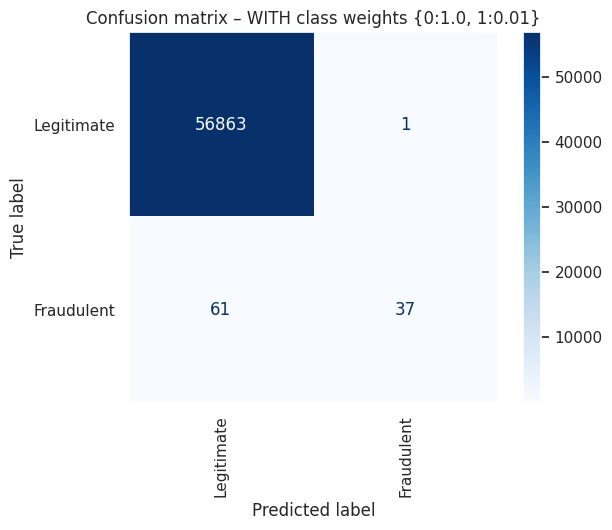

TN=56863  FP=1  FN=61  TP=37
True Positive Rate (fraud caught): 0.3776
False Positive Rate (false alarms): 0.000018
Overall accuracy: 0.99891


In [ ]:

res_after = evaluate_fraud(
    fraud_model_w,
    'Confusion matrix – WITH class weights {0:1.0, 1:0.01}'
)


This reuses the function from Step 9. Compare its output with res_before from Step 10.

Look especially at:
- TP: fraudulent transactions correctly caught.
- FN: fraudulent transactions missed.
- FP: legitimate transactions incorrectly flagged.
- TPR: fraud detection rate.
- FPR: false alarm rate.

**13: Create the comparison table**

In [ ]:

comparison = pd.DataFrame(
    [res_before, res_after],
    index=[
        'No weights',
        'class_weight {0:1, 1:0.01}'
    ]
).round(5)

comparison.to_csv('results/task2_comparison.csv')

comparison


,TN,FP,FN,TP,TPR,FPR,Accuracy
No weights,56856,8,28,70,0.71429,0.00014,0.99937
"class_weight {0:1, 1:0.01}",56863,1,61,37,0.37755,0.00002,0.99891


Explanation:
- pd.DataFrame() combines the results into a table.
- index gives each experiment a name.
- .round(5) rounds values to five decimal places.
- .to_csv() saves the comparison for your assignment.
Your table will contain the following columns:
Model	TN	FP	FN	TP	TPR	FPR	Accuracy
No weights	Your output	Your output	Your output	Your output	Your output	Your output	Your output
Weighted model	Your output	Your output	Your output	Your output	Your output	Your output	Your output

**Task 2e/2f — Analysis answers**

**1. Trade-off:** Assigning a weight of 0.01 to fraudulent transactions tells the model that errors on fraud are much less important than errors on legitimate transactions. This may reduce false alarms, but it can also cause the model to miss more fraudulent transactions. I compared the TPR and FPR of both models to observe this trade-off.

**2. Real-world class weights:** In a practical fraud detection system, we would generally try giving fraudulent transactions a higher weight, such as `{0: 1, 1: 10}`, and tune it according to the results. This encourages the model to pay more attention to the rare fraud class.

**3. Business implications:** A false negative means a fraudulent transaction goes undetected, potentially causing financial losses and chargeback costs. A false positive means a legitimate customer is incorrectly flagged, which can cause inconvenience and reduce customer trust. The best model balances these costs.

**4. Alternative methods:** Other ways to handle class imbalance include oversampling the minority class with methods such as SMOTE, undersampling the majority class, adjusting the prediction threshold, evaluating precision and recall, using the precision-recall curve, and trying ensemble models such as Random Forest or XGBoost.

